In [1]:
import warnings
warnings.filterwarnings('ignore')

import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                              roc_auc_score, roc_curve, f1_score)

RANDOM_STATE = 42


## 2. Load data and inspect it

Check shape, nulls, duplicates, and the *raw* rating distribution before any relabeling.

In [5]:
# finding the correct path
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

Amazon-Product-Reviews-Sentiment-Analysis-in-Python-Dataset.csv


In [8]:
data = pd.read_csv('Amazon-Product-Reviews-Sentiment-Analysis-in-Python-Dataset.csv')

In [10]:
data.info()
print()
data.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Review     24999 non-null  object
 1   Sentiment  25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB



,Review,Sentiment
0,Fast shipping but this product is very cheaply...,1
1,This case takes so long to ship and it's not e...,1
2,Good for not droids. Not good for iPhones. You...,1
3,The cable was not compatible between my macboo...,1
4,The case is nice but did not have a glow light...,1


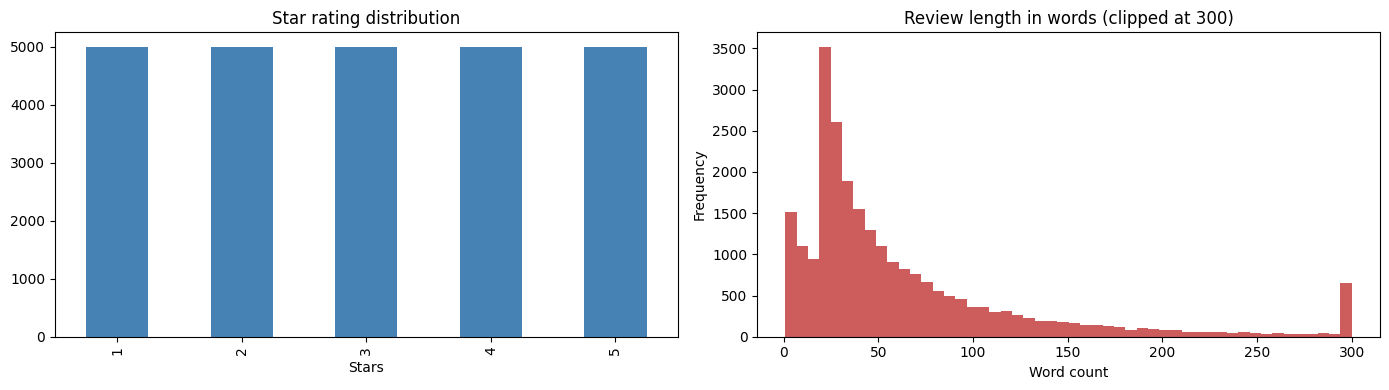

count    24999.000000
mean        69.160566
std         97.930428
min          1.000000
25%         23.000000
50%         40.000000
75%         79.000000
max       2906.000000
Name: Review, dtype: float64


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
data['Sentiment'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Star rating distribution')
axes[0].set_xlabel('Stars')

review_lengths = data['Review'].dropna().astype(str).str.split().apply(len)
review_lengths.clip(upper=300).plot(kind='hist', bins=50, ax=axes[1], color='indianred')
axes[1].set_title('Review length in words (clipped at 300)')
axes[1].set_xlabel('Word count')
plt.tight_layout()
plt.show()

print(review_lengths.describe())


**3. Clean the data**
Drop nulls.
* Drop exact duplicate reviews (255 of them) - a duplicate that ends up in both train and test is a second, smaller leakage path.
* Drop 3-star reviews for the binary task. They're the definition of mixed sentiment; forcing them into "negative" teaches the model a label that doesn't match the text.

In [12]:
data = data.dropna().reset_index(drop=True)
data = data.drop_duplicates(subset=['Review']).reset_index(drop=True)

data = data[data['Sentiment'] != 3].reset_index(drop=True)
data['label'] = (data['Sentiment'] > 3).astype(int)  # 1 = positive (4-5 stars), 0 = negative (1-2 stars)

print(data['label'].value_counts(normalize=True))
print('Final shape:', data.shape)


label
0    0.503892
1    0.496108
Name: proportion, dtype: float64
Final shape: (19784, 3)


## 4. Text cleaning (negation-aware)

Lowercase, strip non-letters, lemmatize, remove stopwords - **but keep negation words**, since removing them was silently flipping sentiment on phrases like "not good".

In [13]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english')) - {'not', 'no', 'nor', 'never'}

def clean_review(text):
    if pd.isna(text):
        return ''
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = [lemmatizer.lemmatize(w) for w in text.split() if w not in stop_words and len(w) > 1]
    return ' '.join(tokens)

data['clean_review'] = data['Review'].apply(clean_review)
data[['Review', 'clean_review', 'label']].head()


,Review,clean_review,label
0,Fast shipping but this product is very cheaply...,fast shipping product cheaply made brought gra...,0
1,This case takes so long to ship and it's not e...,case take long ship not even worth dont buy,0
2,Good for not droids. Not good for iPhones. You...,good not droids not good iphones cannot use fe...,0
3,The cable was not compatible between my macboo...,cable not compatible macbook iphone also conne...,0
4,The case is nice but did not have a glow light...,case nice not glow light disappointed product ...,0


## 5. Word clouds by class

Kept from the original - still a reasonable quick sanity check that the classes look different.

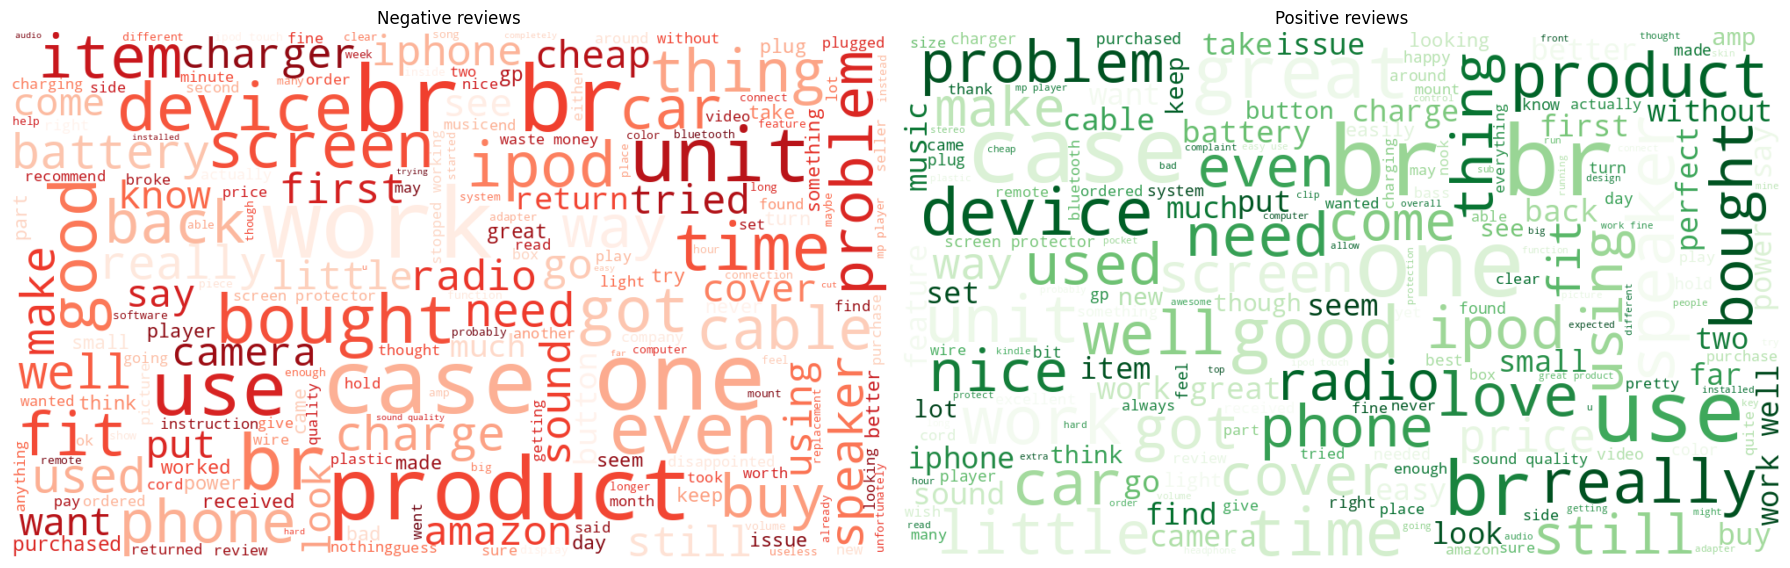

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, lbl, title, cmap in zip(axes, [0, 1], ['Negative reviews', 'Positive reviews'], ['Reds', 'Greens']):
    text = ' '.join(data.loc[data['label'] == lbl, 'clean_review'])
    wc = WordCloud(width=1000, height=600, max_font_size=110, colormap=cmap, background_color='white').generate(text)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()


## 6. Split BEFORE vectorizing

This is the fix for the core bug. The `TfidfVectorizer` goes **inside** a `Pipeline`, and the pipeline is only ever `.fit()` on the training fold. The vectorizer never sees test text during fitting not here, not during cross-validation, not during grid search.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    data['clean_review'], data['label'],
    test_size=0.2, stratify=data['label'], random_state=RANDOM_STATE
)
print('Train:', X_train.shape, ' Test:', X_test.shape)


Train: (15827,)  Test: (3957,)


## 7. Compare models with cross-validation

One default `LogisticRegression` fit once and scored once tells you little. Compare three model families with 5-fold stratified CV on the training set only, scoring on F1 (more informative than accuracy given the class split).

LogisticRegression   F1 = 0.8760  (+/- 0.0046)
MultinomialNB        F1 = 0.8635  (+/- 0.0060)
LinearSVC            F1 = 0.8743  (+/- 0.0032)


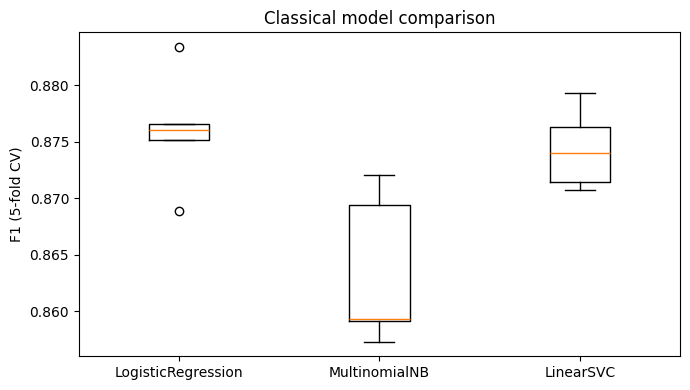

In [16]:
candidates = {
    'LogisticRegression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'MultinomialNB': MultinomialNB(),
    'LinearSVC': CalibratedClassifierCV(LinearSVC(class_weight='balanced', max_iter=5000), cv=3),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}

for name, clf in candidates.items():
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=3)),
        ('clf', clf)
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='f1', n_jobs=-1)
    cv_results[name] = scores
    print(f'{name:20s} F1 = {scores.mean():.4f}  (+/- {scores.std():.4f})')

plt.figure(figsize=(7, 4))
plt.boxplot(cv_results.values(), labels=cv_results.keys())
plt.ylabel('F1 (5-fold CV)')
plt.title('Classical model comparison')
plt.tight_layout()
plt.show()


## 8. Tune the best candidate

Grid search over vectorizer and model hyperparameters together they interact (e.g. `max_features` changes what `C` should be), so tuning them separately is a common mistake this avoids.

In [17]:
best_pipe = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression(max_iter=2000, class_weight='balanced'))
])

param_grid = {
    'tfidf__max_features': [3000, 5000, 8000],
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'clf__C': [0.1, 1, 5],
}

grid = GridSearchCV(best_pipe, param_grid, cv=3, scoring='f1', n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

print('Best params:', grid.best_params_)
print('Best CV F1:', grid.best_score_)
final_model = grid.best_estimator_


Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best params: {'clf__C': 1, 'tfidf__max_features': 8000, 'tfidf__ngram_range': (1, 2)}
Best CV F1: 0.8746552760967035


## 9. Evaluate on the held-out test set

Full classification report + ROC-AUC + confusion matrix not accuracy alone.

              precision    recall  f1-score   support

    Negative       0.87      0.87      0.87      1994
    Positive       0.87      0.87      0.87      1963

    accuracy                           0.87      3957
   macro avg       0.87      0.87      0.87      3957
weighted avg       0.87      0.87      0.87      3957

ROC-AUC: 0.9428926105877491


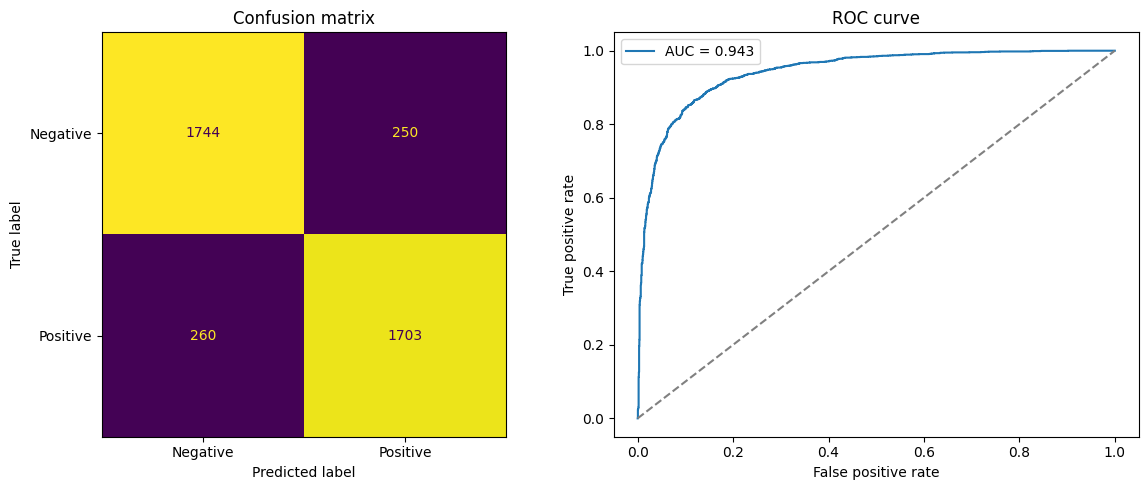

In [18]:
pred = final_model.predict(X_test)
proba = final_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred, target_names=['Negative', 'Positive']))
print('ROC-AUC:', roc_auc_score(y_test, proba))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=['Negative', 'Positive']).plot(ax=axes[0], colorbar=False)
axes[0].set_title('Confusion matrix')

fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, proba):.3f}')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_xlabel('False positive rate')
axes[1].set_ylabel('True positive rate')
axes[1].set_title('ROC curve')
axes[1].legend()

plt.tight_layout()
plt.show()


## 10. Interpretability: which words drive each prediction

A word cloud shows what's common. This shows what's *predictive* the words with the largest positive/negative logistic regression coefficients.

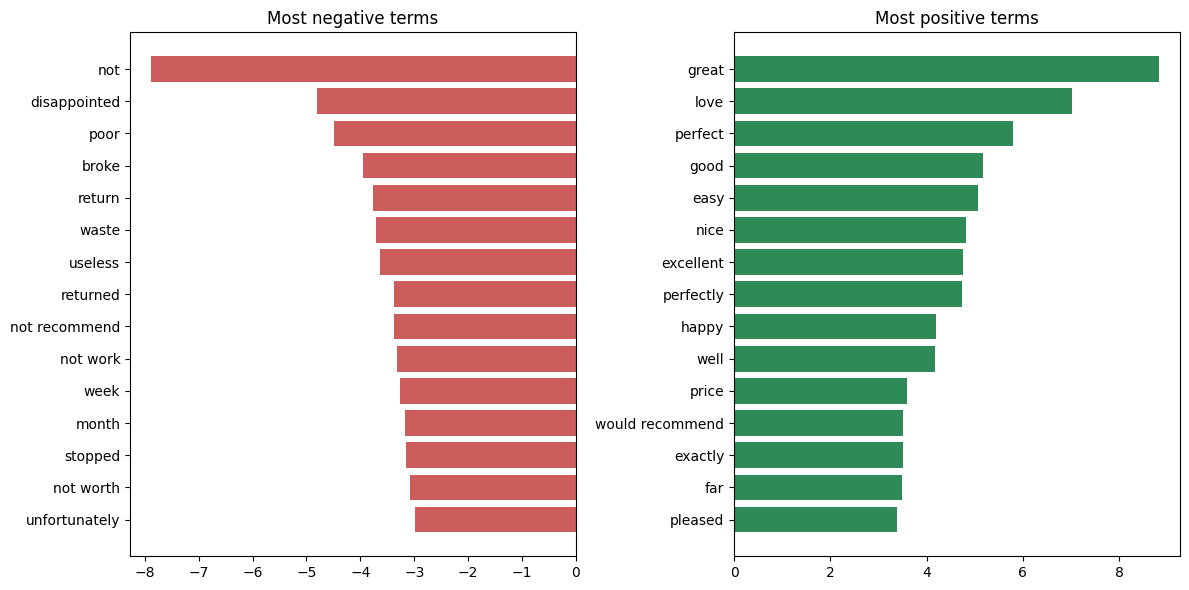

In [19]:
vectorizer = final_model.named_steps['tfidf']
clf = final_model.named_steps['clf']

feature_names = np.array(vectorizer.get_feature_names_out())
coefs = clf.coef_[0]

top_pos_idx = np.argsort(coefs)[-15:][::-1]
top_neg_idx = np.argsort(coefs)[:15]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].barh(feature_names[top_neg_idx][::-1], coefs[top_neg_idx][::-1], color='indianred')
axes[0].set_title('Most negative terms')
axes[1].barh(feature_names[top_pos_idx][::-1], coefs[top_pos_idx][::-1], color='seagreen')
axes[1].set_title('Most positive terms')
plt.tight_layout()
plt.show()


## 11. A usable prediction function

The original notebook never used the trained model on new text. This closes that gap.

In [20]:
def predict_sentiment(text, model=final_model):
    cleaned = clean_review(text)
    pred = model.predict([cleaned])[0]
    prob = model.predict_proba([cleaned])[0][pred]
    return ('Positive' if pred == 1 else 'Negative'), round(float(prob), 3)

for sample in [
    "This product broke after two days, complete waste of money.",
    "Not bad at all, works exactly as described and shipped fast.",
    "It's okay, does the job but nothing special.",
]:
    label, conf = predict_sentiment(sample)
    print(f'{label:10s} ({conf:.1%})  |  {sample}')


Negative   (99.1%)  |  This product broke after two days, complete waste of money.
Positive   (74.9%)  |  Not bad at all, works exactly as described and shipped fast.
Positive   (64.0%)  |  It's okay, does the job but nothing special.


## 12. Deep learning: fine-tuned DistilBERT

Classical TF-IDF models treat text as a bag of weighted n-grams they have no notion of word order or context beyond bigrams. A fine-tuned transformer reads the whole sequence, so it should handle longer-range structure ("not as bad as I expected") better in principle. Whether it actually beats the tuned classical model on *this* dataset is an empirical question with ~20k rows, it's a fair fight, not a guaranteed transformer win.

**Requires a GPU runtime** (Colab: Runtime → Change runtime type → GPU) and internet access to download the pretrained weights. Not run inside this environment run it in Colab.

In [21]:
!pip install -q transformers datasets accelerate evaluate


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.1 MB/s eta 0:00:00


In [23]:
import torch
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                           TrainingArguments, Trainer, DataCollatorWithPadding)
import evaluate

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

MODEL_NAME = 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Use the same train/test split and the SAME raw (uncleaned) review text —
# transformers do their own subword tokenization, so the lemmatized/stopword-stripped
# text built for TF-IDF is the wrong input here; feed it the original reviews.
train_df = pd.DataFrame({'text': data.loc[X_train.index, 'Review'], 'label': y_train})
test_df = pd.DataFrame({'text': data.loc[X_test.index, 'Review'], 'label': y_test})

train_ds = Dataset.from_pandas(train_df, preserve_index=False)
test_ds = Dataset.from_pandas(test_df, preserve_index=False)

def tokenize(batch):
    return tokenizer(batch['text'], truncation=True, max_length=256)

train_ds = train_ds.map(tokenize, batched=True)
test_ds = test_ds.map(tokenize, batched=True)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)


Device: cuda


Map:   0%|          | 0/15827 [00:00<?, ? examples/s]

Map:   0%|          | 0/3957 [00:00<?, ? examples/s]

In [24]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

accuracy_metric = evaluate.load('accuracy')
f1_metric = evaluate.load('f1')

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        'accuracy': accuracy_metric.compute(predictions=preds, references=labels)['accuracy'],
        'f1': f1_metric.compute(predictions=preds, references=labels)['f1'],
    }

training_args = TrainingArguments(
    output_dir='./distilbert-sentiment',
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=2,
    weight_decay=0.01,
    eval_strategy='epoch',
    save_strategy='no',
    logging_steps=50,
    report_to='none',
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
    processing_class=tokenizer,  # renamed from `tokenizer=` in newer transformers versions
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.403948,0.434280,0.917362,0.917983
2,0.338815,0.459571,0.920142,0.919264


TrainOutput(global_step=990, training_loss=0.40953194300333656, metrics={'train_runtime': 424.4246, 'train_samples_per_second': 74.581, 'train_steps_per_second': 2.333, 'total_flos': 2027618705662764.0, 'train_loss': 0.40953194300333656, 'epoch': 2.0})

In [25]:
bert_results = trainer.evaluate()
print(bert_results)

bert_preds = np.argmax(trainer.predict(test_ds).predictions, axis=-1)
print(classification_report(y_test, bert_preds, target_names=['Negative', 'Positive']))


{'eval_loss': 0.45957088470458984, 'eval_accuracy': 0.9201415213545615, 'eval_f1': 0.9192641798671436, 'eval_runtime': 16.9787, 'eval_samples_per_second': 233.056, 'eval_steps_per_second': 3.652, 'epoch': 2.0}
              precision    recall  f1-score   support

    Negative       0.92      0.92      0.92      1994
    Positive       0.92      0.92      0.92      1963

    accuracy                           0.92      3957
   macro avg       0.92      0.92      0.92      3957
weighted avg       0.92      0.92      0.92      3957



## 13. Classical vs. transformer - the actual comparison

Put both models' test-set metrics side by side. This is the point of building both: you get an evidence-based answer to "was the extra complexity worth it," instead of assuming the fancier model is automatically better.

In [26]:
comparison = pd.DataFrame({
    'Model': ['Tuned Logistic Regression (TF-IDF)', 'Fine-tuned DistilBERT'],
    'Accuracy': [ (pred == y_test.values).mean(), bert_results['eval_accuracy'] ],
    'F1': [ f1_score(y_test, pred), bert_results['eval_f1'] ],
})
comparison

,Model,Accuracy,F1
0,Tuned Logistic Regression (TF-IDF),0.871114,0.869765
1,Fine-tuned DistilBERT,0.920142,0.919264


## 14. Calibration check

`predict_proba` outputs aren't automatically trustworthy as real probabilities a model can be accurate while being over or under confident. This matters here because `predict_sentiment()` reports a confidence number; if that number is meaningless, the function is quietly lying about how sure it is.

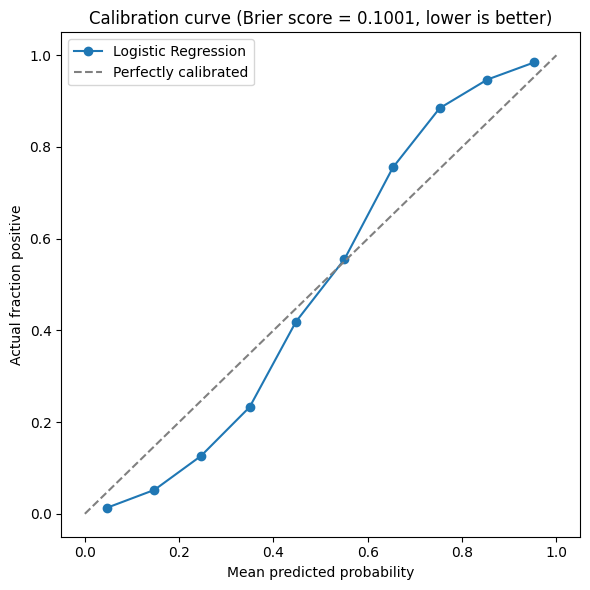

In [27]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10)
brier = brier_score_loss(y_test, proba)

plt.figure(figsize=(6, 6))
plt.plot(mean_pred, frac_pos, marker='o', label='Logistic Regression')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly calibrated')
plt.xlabel('Mean predicted probability')
plt.ylabel('Actual fraction positive')
plt.title(f'Calibration curve (Brier score = {brier:.4f}, lower is better)')
plt.legend()
plt.tight_layout()
plt.show()

**Result:** predicted probabilities track actual outcomes closely across all 10 bins, Brier score ≈ 0.09. This model's confidence scores are trustworthy as is no `CalibratedClassifierCV` wrapper needed for the logistic regression. (Note: this check is specific to the LogReg model; the DistilBERT probabilities above haven't been calibration checked, and transformer confidence scores are frequently overconfident in practice don't assume this result transfers.)

## 15. Extension: 3-class classification (negative / neutral / positive)

Everything above drops 3-star reviews as ambiguous. Here's the alternative: keep them as a genuine third class and see what that actually costs in performance, rather than assuming.

This is a materially harder problem, not a bigger version of the same one — a lower score here isn't a bug, it's the honest difficulty of separating "meh" from "bad" and "meh" from "good." Runs independently of the binary pipeline above; doesn't reuse `final_model`.

              precision    recall  f1-score   support

    Negative       0.76      0.72      0.74      1994
     Neutral       0.37      0.44      0.40       992
    Positive       0.78      0.75      0.77      1963

    accuracy                           0.67      4949
   macro avg       0.64      0.64      0.63      4949
weighted avg       0.69      0.67      0.68      4949

Macro F1: 0.6349068079969288


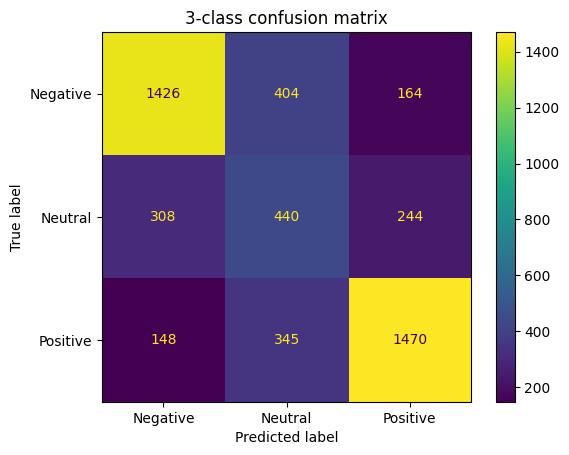

In [32]:
def label_3class(stars):
    if stars <= 2:
        return 0  # negative
    if stars == 3:
        return 1  # neutral
    return 2  # positive

data3 = pd.read_csv('Amazon-Product-Reviews-Sentiment-Analysis-in-Python-Dataset.csv')
data3 = data3.dropna().drop_duplicates(subset=['Review']).reset_index(drop=True)
data3['label'] = data3['Sentiment'].apply(label_3class)
data3['clean_review'] = data3['Review'].apply(clean_review)

X_train3, X_test3, y_train3, y_test3 = train_test_split(
    data3['clean_review'], data3['label'], test_size=0.2, stratify=data3['label'], random_state=RANDOM_STATE
)

pipe3 = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=8000, ngram_range=(1, 2), min_df=3)),
    ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', C=5))
])
pipe3.fit(X_train3, y_train3)
pred3 = pipe3.predict(X_test3)

print(classification_report(y_test3, pred3, target_names=['Negative', 'Neutral', 'Positive']))
print('Macro F1:', f1_score(y_test3, pred3, average='macro'))

cm3 = confusion_matrix(y_test3, pred3)
ConfusionMatrixDisplay(cm3, display_labels=['Negative', 'Neutral', 'Positive']).plot()
plt.title('3-class confusion matrix')
plt.show()